# Signal 1 default model

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
import xgboost as xgb
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

SEED = 42
PROCESSED_DIR = Path("../data/processed")
COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # Okabe-Ito, colorblind-safe

TARGET = "default"
# Lender 1 sees the shared features plus its own signal1
FEATURES = ["sex", "employment", "married", "income", "signal1"]
CATEGORICAL = ["sex", "employment"]

# Same 5 CV folds on train for every model; the test split is never used for tuning
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Seed: {SEED} | scikit-learn {sklearn.__version__}, xgboost {xgb.__version__}, optuna {optuna.__version__}")

Seed: 42 | scikit-learn 1.6.1, xgboost 3.1.2, optuna 4.5.0


## 1. Load the shared split

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

for name, part in [("train", train), ("test", test)]:
    print(f"{name}: {len(part):,} rows, default rate {part[TARGET].mean():.2%}")

# Check the files come from the shared split
assert (len(train), len(test)) == (70_000, 30_000), "unexpected split sizes: re-run eda_and_split.ipynb"
assert not set(train["id"]) & set(test["id"]), "a borrower appears in both train and test"

train: 70,000 rows, default rate 9.95%
test: 30,000 rows, default rate 9.95%


## 2. Features and target

In [3]:
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
test_ids = test["id"]

X_train.head()

,sex,employment,married,income,signal1
0,F,employed,1,15064,0.594949
1,M,employed,0,6816,0.000000
2,M,student,0,0,0.723660
3,M,employed,1,28404,0.000000
4,F,employed,0,7030,0.027674


## 3. Evaluation and baseline

In [4]:
def evaluate(y_true: np.ndarray, p_pred: np.ndarray) -> dict[str, float]:
    """Log loss, Brier score and AUC of predicted default probabilities."""
    return {
        "log_loss": log_loss(y_true, p_pred),
        "brier": brier_score_loss(y_true, p_pred),
        "auc": roc_auc_score(y_true, p_pred),
    }


def plot_calibration(
    y_true: np.ndarray, probs: dict[str, np.ndarray], title: str = "Calibration on the test split", n_bins: int = 10
) -> None:
    """Plot observed default rate vs mean predicted probability per quantile bin."""
    _, ax = plt.subplots(figsize=(5.5, 5))
    top = 0.0
    for (name, p), color in zip(probs.items(), COLORS):
        observed, predicted = calibration_curve(y_true, p, n_bins=n_bins, strategy="quantile")
        ax.plot(predicted * 100, observed * 100, marker="o", color=color, label=name)
        top = max(top, predicted.max(), observed.max())
    ax.plot([0, top * 100], [0, top * 100], ls="--", lw=1, color="black", label="Perfect calibration")
    ax.set(title=title, xlabel="Mean predicted default probability (%)",
           ylabel="Observed default rate (%)")
    ax.legend()
    plt.show()


def calibration_slope(y_true: np.ndarray, p_pred: np.ndarray) -> tuple[float, float]:
    """Calibration slope and intercept from refitting y on logit(p)."""
    p = np.clip(p_pred, 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    fit = LogisticRegression(C=np.inf).fit(logit, y_true)
    return fit.coef_[0][0], fit.intercept_[0]

In [5]:
results = {}
test_probs = {}

dummy = DummyClassifier(strategy="prior")
dummy_cv = -cross_val_score(dummy, X_train, y_train, cv=CV, scoring="neg_log_loss")
test_probs["dummy (prior)"] = dummy.fit(X_train, y_train).predict_proba(X_test)[:, 1]
results["dummy (prior)"] = {"cv_log_loss": dummy_cv.mean(), "cv_std": dummy_cv.std(), **evaluate(y_test, test_probs["dummy (prior)"])}

pd.DataFrame(results).T.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5


## 4. Logistic regression

Three income versions are compared on CV log loss; the best one is then refit without `signal1`.

In [6]:
def add_income_features(X: pd.DataFrame) -> pd.DataFrame:
    """Add log income and a zero-income flag."""
    X = X.copy()
    X["log_income"] = np.log1p(X["income"])
    X["zero_income"] = (X["income"] == 0).astype(int)
    return X


def fit_logreg(X: pd.DataFrame, y: pd.Series, numeric: list[str]) -> GridSearchCV:
    """Tune C by 5-fold CV log loss on the training set, then refit on all of it."""
    pipe = Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(drop="first"), CATEGORICAL),
            ("num", StandardScaler(), numeric),
        ])),
        ("model", LogisticRegression(max_iter=1000)),
    ])
    grid = {"model__C": [0.01, 0.1, 1, 10, 100, 1000]}
    return GridSearchCV(pipe, grid, cv=CV, scoring="neg_log_loss").fit(X, y)


X_train_lr, X_test_lr = add_income_features(X_train), add_income_features(X_test)

### Income variants (with signal 1)

In [7]:
INCOME_VARIANTS = {
    "raw": ["income"],
    "log": ["log_income"],
    "log + zero flag": ["log_income", "zero_income"],
}
searches = {
    name: fit_logreg(X_train_lr, y_train, cols + ["married", "signal1"]) for name, cols in INCOME_VARIANTS.items()
}
pd.DataFrame({
    "cv_log_loss": {name: -s.best_score_ for name, s in searches.items()},
    "best_C": {name: s.best_params_["model__C"] for name, s in searches.items()},
}).round(4)

,cv_log_loss,best_C
raw,0.2935,10.0
log,0.3054,0.1
log + zero flag,0.2941,10.0


### With vs without signal 1

The gap between the two rows is what `signal1` adds to the shared features.

In [8]:
best_income = min(searches, key=lambda name: -searches[name].best_score_)
print(f"Best income version (lowest CV log loss): {best_income}")

shared_only = fit_logreg(X_train_lr, y_train, INCOME_VARIANTS[best_income] + ["married"])
for name, search in [("logreg (shared only)", shared_only), ("logreg + signal1", searches[best_income])]:
    test_probs[name] = search.predict_proba(X_test_lr)[:, 1]
    results[name] = {"cv_log_loss": -search.best_score_, "cv_std": search.cv_results_["std_test_score"][search.best_index_],
                     **evaluate(y_test, test_probs[name])}

pd.DataFrame(results).T.round(4)

Best income version (lowest CV log loss): raw


,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000
logreg (shared only),0.2958,0.0009,0.2971,0.0849,0.7168
logreg + signal1,0.2935,0.0012,0.2943,0.0842,0.7289


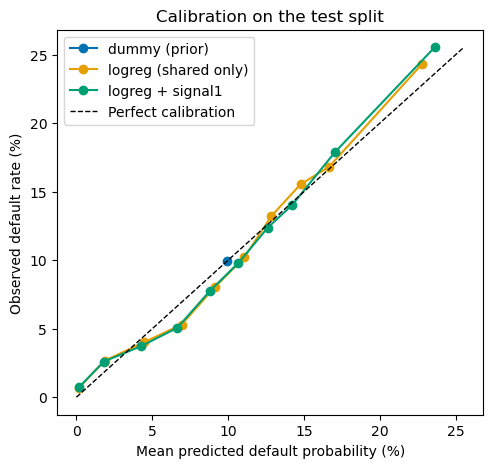

In [9]:
plot_calibration(y_test, test_probs)

## 5. XGBoost

Optuna tunes the hyperparameters on the same 5-fold CV log loss; early stopping sets the number of trees.

In [10]:
X_train_xgb = pd.get_dummies(X_train, columns=CATEGORICAL, dtype=int)
X_test_xgb = pd.get_dummies(X_test, columns=CATEGORICAL, dtype=int).reindex(columns=X_train_xgb.columns, fill_value=0)
dtrain = xgb.DMatrix(X_train_xgb, label=y_train)
folds = list(CV.split(X_train_xgb, y_train))  # same CV folds as the logistic regression

BASE_PARAMS = {"objective": "binary:logistic", "eval_metric": "logloss", "tree_method": "hist", "seed": SEED}
N_TRIALS = 40


def objective(trial: optuna.Trial) -> float:
    params = BASE_PARAMS | {
        "eta": trial.suggest_float("eta", 0.02, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "lambda": trial.suggest_float("lambda", 1e-3, 10, log=True),
    }
    cv = xgb.cv(params, dtrain, num_boost_round=1000, folds=folds, early_stopping_rounds=50, verbose_eval=False)
    trial.set_user_attr("n_rounds", len(cv))
    trial.set_user_attr("cv_std", cv["test-logloss-std"].iloc[-1])
    return cv["test-logloss-mean"].iloc[-1]


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)

best_params = BASE_PARAMS | study.best_params
n_rounds = study.best_trial.user_attrs["n_rounds"]
print(f"Best CV log loss: {study.best_value:.4f} with {n_rounds} trees")
study.best_params

Best CV log loss: 0.2909 with 349 trees


{'eta': 0.055369650523271106,
 'max_depth': 2,
 'min_child_weight': 1.0415813060989965,
 'subsample': 0.6593942969383783,
 'colsample_bytree': 0.5022557221749966,
 'lambda': 0.0076465413663042705}

### Calibration check on out-of-fold predictions

Done on train only: if the points sit on the diagonal, no recalibration step is needed.

Out-of-fold log loss: 0.2910 | mean predicted 9.94% vs observed 9.95%
Calibration slope 1.008, intercept 0.016


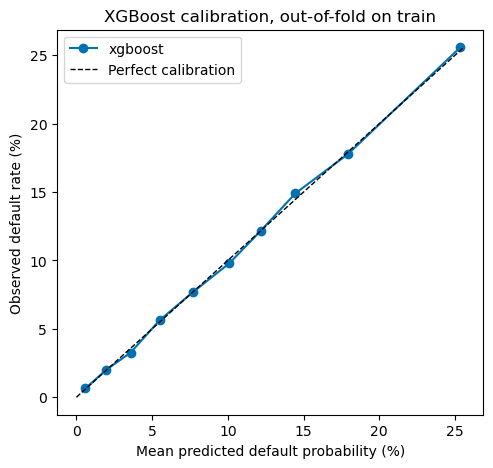

In [11]:
oof = np.zeros(len(y_train))
for fit_idx, val_idx in folds:
    booster = xgb.train(best_params, dtrain.slice(fit_idx), num_boost_round=n_rounds)
    oof[val_idx] = booster.predict(dtrain.slice(val_idx))

print(f"Out-of-fold log loss: {log_loss(y_train, oof):.4f} | mean predicted {oof.mean():.2%} "
      f"vs observed {y_train.mean():.2%}")
slope, intercept = calibration_slope(y_train, oof)
print(f"Calibration slope {slope:.3f}, intercept {intercept:.3f}")
plot_calibration(y_train, {"xgboost": oof}, title="XGBoost calibration, out-of-fold on train")

### Final XGBoost fit and test scores

In [12]:
booster = xgb.train(best_params, dtrain, num_boost_round=n_rounds)
test_probs["xgboost"] = booster.predict(xgb.DMatrix(X_test_xgb))
results["xgboost"] = {"cv_log_loss": study.best_value, "cv_std": study.best_trial.user_attrs["cv_std"],
                      **evaluate(y_test, test_probs["xgboost"])}

pd.DataFrame(results).T.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000
logreg (shared only),0.2958,0.0009,0.2971,0.0849,0.7168
logreg + signal1,0.2935,0.0012,0.2943,0.0842,0.7289
xgboost,0.2909,0.0010,0.2904,0.0834,0.7364


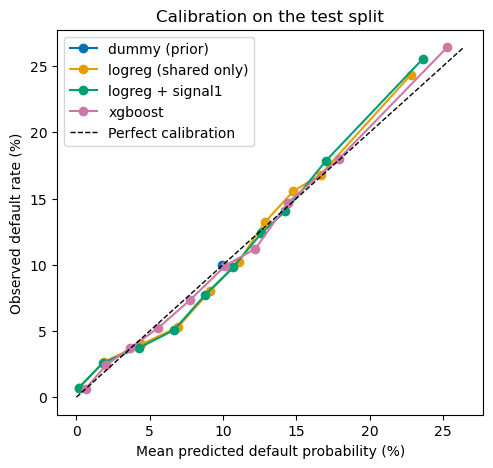

In [13]:
plot_calibration(y_test, test_probs)

## 6. Spline logistic regression

Splines on `signal1` and log income, with and without a `signal1 == 0` indicator; knots and C tuned on CV log loss.

In [14]:
def fit_spline_logreg(X: pd.DataFrame, y: pd.Series, passthrough: list[str]) -> GridSearchCV:
    """Tune knots and C by 5-fold CV log loss on the training set, then refit on all of it."""
    pipe = Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(drop="first"), CATEGORICAL),
            ("spline", SplineTransformer(degree=3, knots="quantile"), ["signal1", "log_income"]),
            ("bin", "passthrough", passthrough),
        ])),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    grid = {"prep__spline__n_knots": [6, 8, 10, 12], "model__C": [1, 10, 100, 1000, 10000]}
    return GridSearchCV(pipe, grid, cv=CV, scoring="neg_log_loss").fit(X, y)


# signal1 == 0 indicator, since a spline cannot jump at exactly 0
# Log income: a raw-income spline drove PDs toward 0 in the 1M-capped tail
X_train_sp = X_train.assign(signal1_zero=(X_train["signal1"] == 0).astype(int), log_income=np.log1p(X_train["income"]))
X_test_sp = X_test.assign(signal1_zero=(X_test["signal1"] == 0).astype(int), log_income=np.log1p(X_test["income"]))

spline_searches = {
    "spline logreg": fit_spline_logreg(X_train_sp, y_train, ["married"]),
    "spline logreg + zero flag": fit_spline_logreg(X_train_sp, y_train, ["married", "signal1_zero"]),
}
pd.DataFrame({
    "cv_log_loss": {name: -s.best_score_ for name, s in spline_searches.items()},
    "n_knots": {name: s.best_params_["prep__spline__n_knots"] for name, s in spline_searches.items()},
    "best_C": {name: s.best_params_["model__C"] for name, s in spline_searches.items()},
}).round(4)

,cv_log_loss,n_knots,best_C
spline logreg,0.2909,10,10
spline logreg + zero flag,0.2909,10,1


In [15]:
for name, search in spline_searches.items():
    test_probs[name] = search.predict_proba(X_test_sp)[:, 1]
    results[name] = {"cv_log_loss": -search.best_score_, "cv_std": search.cv_results_["std_test_score"][search.best_index_],
                     **evaluate(y_test, test_probs[name])}

pd.DataFrame(results).T.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000
logreg (shared only),0.2958,0.0009,0.2971,0.0849,0.7168
logreg + signal1,0.2935,0.0012,0.2943,0.0842,0.7289
xgboost,0.2909,0.0010,0.2904,0.0834,0.7364
spline logreg,0.2909,0.0010,0.2905,0.0834,0.7361
spline logreg + zero flag,0.2909,0.0010,0.2903,0.0833,0.7368


### Learned effect of signal 1

Mean predicted PD vs observed default rate per `signal1` bin on the test split.

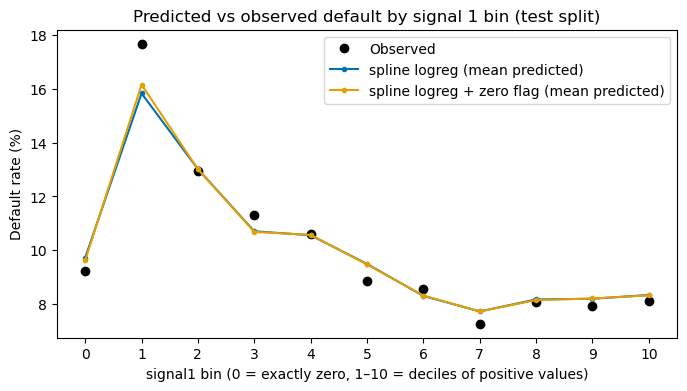

In [16]:
# Same bins as the EDA: exactly 0, then deciles of the positive values
positive = X_test_sp["signal1"] > 0
signal_bin = pd.Series(0, index=X_test_sp.index)
signal_bin[positive] = pd.qcut(X_test_sp.loc[positive, "signal1"], 10, labels=False) + 1
by_bin = pd.DataFrame({"observed": y_test, **{name: test_probs[name] for name in spline_searches}},
                      index=X_test_sp.index).groupby(signal_bin).mean() * 100

_, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_bin.index, by_bin["observed"], "o", color="black", label="Observed")
for name, color in zip(spline_searches, COLORS):
    ax.plot(by_bin.index, by_bin[name], marker=".", color=color, label=f"{name} (mean predicted)")
ax.set(title="Predicted vs observed default by signal 1 bin (test split)",
       xlabel="signal1 bin (0 = exactly zero, 1–10 = deciles of positive values)", ylabel="Default rate (%)",
       xticks=range(11))
ax.legend()
plt.show()

## 7. Compare and export

Final table on the test split; the model with the lowest CV log loss is exported.

In [17]:
comparison = pd.DataFrame(results).T.sort_values("cv_log_loss")
comparison.round(4)

,cv_log_loss,cv_std,log_loss,brier,auc
spline logreg + zero flag,0.2909,0.0010,0.2903,0.0833,0.7368
xgboost,0.2909,0.0010,0.2904,0.0834,0.7364
spline logreg,0.2909,0.0010,0.2905,0.0834,0.7361
logreg + signal1,0.2935,0.0012,0.2943,0.0842,0.7289
logreg (shared only),0.2958,0.0009,0.2971,0.0849,0.7168
dummy (prior),0.3239,0.0001,0.3239,0.0896,0.5000


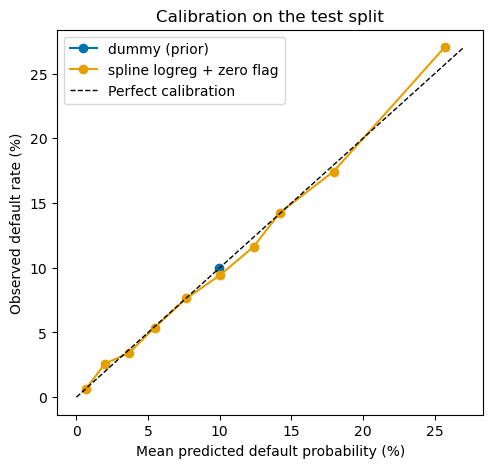

In [18]:
selected = comparison.index[0]  # exported model = lowest CV log loss
EXPORT = {selected: selected.split()[0]}  # model name -> file tag
plot_calibration(y_test, {name: test_probs[name] for name in ["dummy (prior)", *EXPORT]})

In [19]:
THRESHOLD = 0.5  # agreed output format only; pricing uses pd

for name, tag in EXPORT.items():
    predictions = pd.DataFrame({
        "id": test_ids,
        "pd": test_probs[name],
        "pred": (test_probs[name] >= THRESHOLD).astype(int),
        "threshold": THRESHOLD,
    })
    path = PROCESSED_DIR / f"signal1_test_predictions_{tag}.csv"
    predictions.to_csv(path, index=False)
    print(f"{path.name}: {len(predictions):,} rows, {predictions['pred'].sum()} predicted defaults at {THRESHOLD}")

comparison.round(4).to_csv(PROCESSED_DIR / "signal1_metrics.csv", index_label="model")

# Best settings saved for the report and for reuse on the other signals
best_settings = {
    "logreg + signal1": {"income": best_income, **searches[best_income].best_params_},
    **{name: search.best_params_ for name, search in spline_searches.items()},
    "xgboost": {**study.best_params, "n_rounds": n_rounds},
}
(PROCESSED_DIR / "signal1_best_params.json").write_text(json.dumps(best_settings, indent=2))
print("Saved signal1_metrics.csv and signal1_best_params.json")

signal1_test_predictions_spline.csv: 30,000 rows, 0 predicted defaults at 0.5
Saved signal1_metrics.csv and signal1_best_params.json
